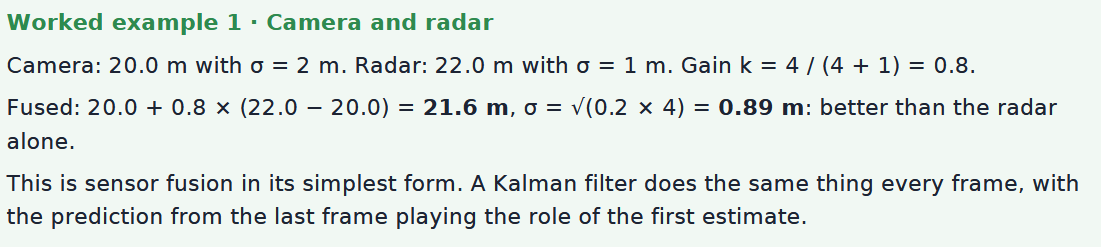

In [1]:
import numpy as np

def fuse(mu_a, var_a, mu_b, var_b):
    """Combine two independent Gaussian estimates of the same quantity."""
    k = var_a / (var_a + var_b)          # how much to trust b relative to a
    mu = mu_a + k * (mu_b - mu_a)
    var = (1 - k) * var_a                # = 1 / (1/var_a + 1/var_b)
    return mu, var, k

# camera says the car is 20.0 m away (sigma 2 m), radar says 22.0 m (sigma 1 m)
mu, var, k = fuse(20.0, 2.0**2, 22.0, 1.0**2)
print(f"fused: {mu:.2f} m, sigma {np.sqrt(var):.3f} m, weight on radar {k:.2f}")

fused: 21.60 m, sigma 0.894 m, weight on radar 0.80


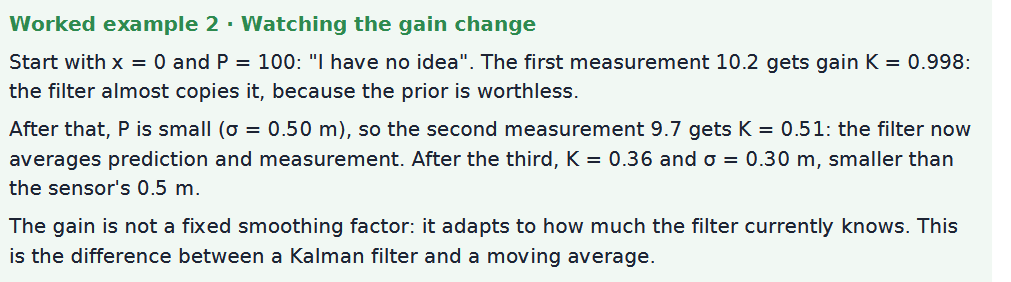

In [1]:
import numpy as np

def kf1d_step(x, P, z, q, r):
    """One cycle of a 1D Kalman filter with a constant-position model."""
    x_pred, P_pred = x, P + q            # predict: the state may have drifted by q
    K = P_pred / (P_pred + r)            # Kalman gain
    x_new = x_pred + K * (z - x_pred)    # update with the innovation z - x_pred
    P_new = (1 - K) * P_pred
    return x_new, P_new, K

x, P = 0.0, 100.0                        # start: no idea where it is (large P)
# measurements of a target at 10 m, sensor sigma 0.5 m
for z in [10.2, 9.7, 10.4]:
    x, P, K = kf1d_step(x, P, z, q=0.01, r=0.25)
    print(f"z = {z:5.1f}  ->  x = {x:6.3f}, sigma = {np.sqrt(P):.3f}, K = {K:.3f}")

z =  10.2  ->  x = 10.175, sigma = 0.499, K = 0.998
z =   9.7  ->  x =  9.933, sigma = 0.357, K = 0.509
z =  10.4  ->  x = 10.099, sigma = 0.298, K = 0.355


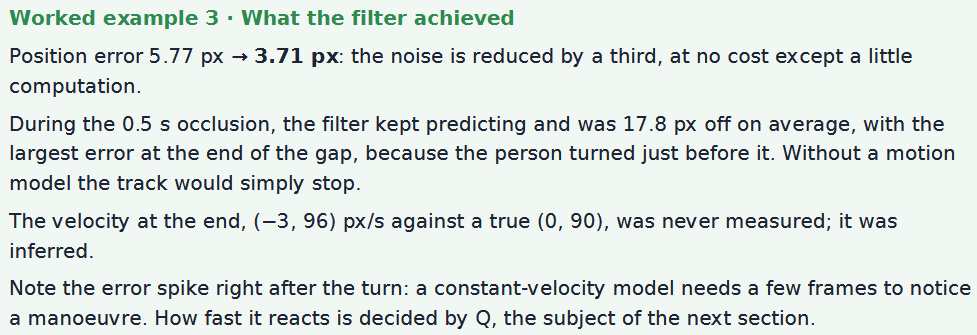

position error: raw detections 5.77 px, Kalman filter 3.71 px
during the 0.5 s occlusion (prediction only): 17.83 px
velocity at the end: (-3.0, 96.4) px/s, true (0.0, 90.0)


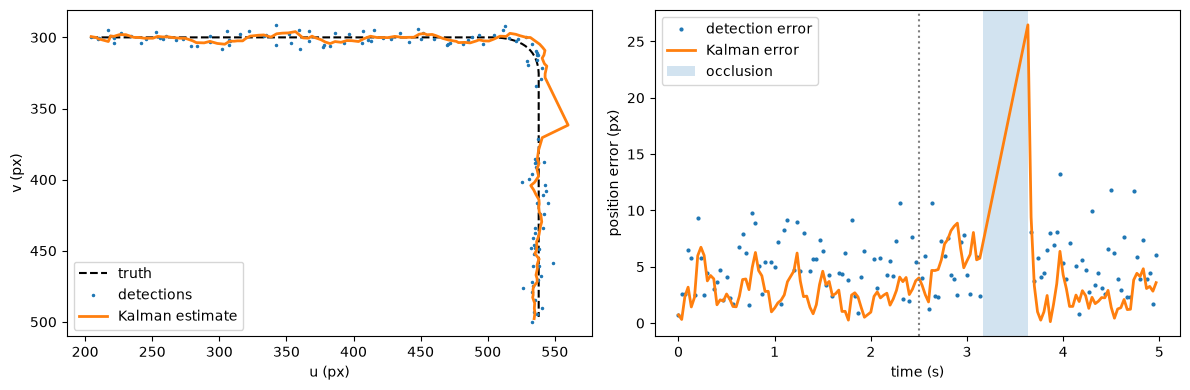

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# ---------- Kalman filter and constant-velocity model ----------
class KalmanFilter:
    """Linear Kalman filter: x' = F x + w,  z = H x + v,  w ~ N(0, Q),  v ~ N(0, R)."""
    def __init__(self, F, H, Q, R, x0, P0):
        self.F, self.H, self.Q, self.R = F, H, Q, R
        self.x, self.P = x0.astype(float), P0.astype(float)

    def predict(self):
        self.x = self.F @ self.x
        self.P = self.F @ self.P @ self.F.T + self.Q
        return self.x

    def update(self, z):
        y = z - self.H @ self.x                      # innovation
        S = self.H @ self.P @ self.H.T + self.R      # innovation covariance
        K = self.P @ self.H.T @ np.linalg.inv(S)     # Kalman gain
        self.x = self.x + K @ y
        self.P = (np.eye(len(self.x)) - K @ self.H) @ self.P
        return y, S

def constant_velocity_model(dt, q, r):
    """State [x, y, vx, vy], measurement [x, y]; q: acceleration noise, r: meas. std."""
    F = np.array([[1, 0, dt, 0], [0, 1, 0, dt], [0, 0, 1, 0], [0, 0, 0, 1]], float)
    H = np.array([[1, 0, 0, 0], [0, 1, 0, 0]], float)
    G = np.array([[dt**2 / 2, 0], [0, dt**2 / 2], [dt, 0], [0, dt]])
    Q = q**2 * G @ G.T                               # white-noise acceleration
    R = r**2 * np.eye(2)
    return F, H, Q, R

# ---------- simulated pedestrian: right, then turning down ----------
rng = np.random.default_rng(0)
dt, n = 1 / 30, 150
t = np.arange(n) * dt
vx = np.where(t < 2.5, 120.0, 120.0 * np.clip(1 - (t - 2.5) / 0.6, 0, 1))   # px/s
vy = np.where(t < 2.5, 0.0, 90.0 * np.clip((t - 2.5) / 0.6, 0, 1))
truth = np.c_[200 + np.cumsum(vx) * dt, 300 + np.cumsum(vy) * dt]

meas = truth + rng.normal(0, 4.0, truth.shape)          # detector noise: 4 px
missed = rng.random(n) < 0.15                            # 15 % missed detections
missed[95:110] = True                                    # plus a short occlusion

# ---------- run the filter ----------
F, H, Q, R = constant_velocity_model(dt, q=150.0, r=4.0)
kf = KalmanFilter(F, H, Q, R, x0=np.r_[meas[0], 0, 0], P0=np.diag([16, 16, 1e4, 1e4]))
est = [kf.x[:2].copy()]
for k in range(1, n):
    kf.predict()
    if not missed[k]:
        kf.update(meas[k])
    est.append(kf.x[:2].copy())
est = np.array(est)

# ---------- results ----------
ok = ~missed
rmse_raw = np.sqrt(np.mean(np.sum((meas[ok] - truth[ok]) ** 2, axis=1)))
rmse_kf = np.sqrt(np.mean(np.sum((est[ok] - truth[ok]) ** 2, axis=1)))
gap = slice(95, 110)
gap_err = np.sqrt(np.mean(np.sum((est[gap] - truth[gap]) ** 2, axis=1)))
print(f"position error: raw detections {rmse_raw:.2f} px, Kalman filter {rmse_kf:.2f} px")
print(f"during the 0.5 s occlusion (prediction only): {gap_err:.2f} px")
print(f"velocity at the end: ({kf.x[2]:.1f}, {kf.x[3]:.1f}) px/s, true (0.0, 90.0)")

# ---------- plot: path and error over time ----------
err_raw = np.linalg.norm(meas - truth, axis=1)
err_kf = np.linalg.norm(est - truth, axis=1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(truth[:, 0], truth[:, 1], "k--", label="truth")
ax[0].plot(meas[ok, 0], meas[ok, 1], ".", ms=3, label="detections")
ax[0].plot(est[:, 0], est[:, 1], lw=2, label="Kalman estimate")
ax[0].invert_yaxis(); ax[0].set_xlabel("u (px)"); ax[0].set_ylabel("v (px)"); ax[0].legend()
ax[1].plot(t[ok], err_raw[ok], ".", ms=4, label="detection error")
ax[1].plot(t, err_kf, lw=2, label="Kalman error")
ax[1].axvspan(t[95], t[109], alpha=0.2, label="occlusion")
ax[1].axvline(2.5, ls=":", c="gray")
ax[1].set_xlabel("time (s)"); ax[1].set_ylabel("position error (px)"); ax[1].legend()
plt.tight_layout(); plt.show()

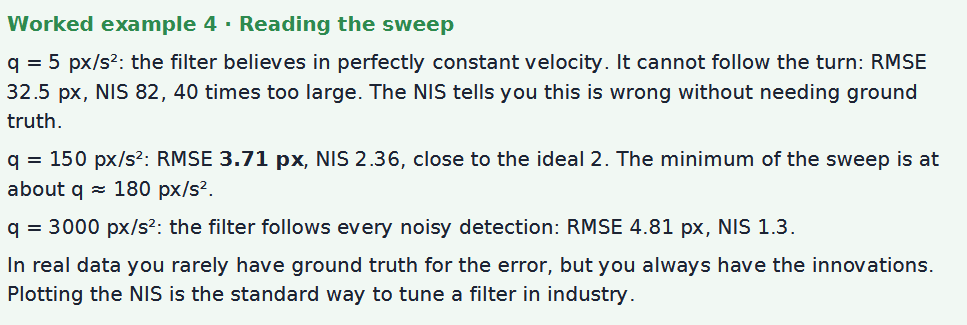

q =     5 px/s^2: RMSE 32.53 px, mean NIS 81.95  (ideal: 2.0)
q =    30 px/s^2: RMSE  8.16 px, mean NIS  7.72  (ideal: 2.0)
q =   150 px/s^2: RMSE  3.71 px, mean NIS  2.36  (ideal: 2.0)
q =   600 px/s^2: RMSE  3.98 px, mean NIS  1.77  (ideal: 2.0)
q =  3000 px/s^2: RMSE  4.81 px, mean NIS  1.32  (ideal: 2.0)
lowest RMSE at q = 202 px/s^2 (3.67 px)


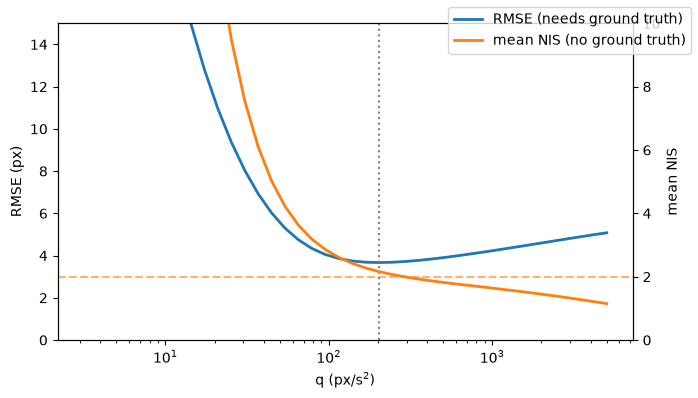

In [3]:
def run_filter(q, r_assumed=4.0):
    """Run the Example 3 filter with acceleration noise q; return RMSE and mean NIS."""
    F, H, Q, R = constant_velocity_model(dt, q=q, r=r_assumed)
    kf = KalmanFilter(F, H, Q, R, x0=np.r_[meas[0], 0, 0], P0=np.diag([16, 16, 1e4, 1e4]))
    out, nis = [kf.x[:2].copy()], []
    for k in range(1, n):
        kf.predict()
        if not missed[k]:
            y, S_ = kf.update(meas[k])
            nis.append(y @ np.linalg.inv(S_) @ y)    # normalised innovation squared
        out.append(kf.x[:2].copy())
    e = np.array(out)[ok] - truth[ok]
    return np.sqrt(np.mean(np.sum(e**2, axis=1))), np.mean(nis[10:])   # skip start-up

for q in [5, 30, 150, 600, 3000]:
    rmse, nis = run_filter(q)
    print(f"q = {q:5d} px/s^2: RMSE {rmse:5.2f} px, mean NIS {nis:5.2f}  (ideal: 2.0)")

# ---------- full sweep: RMSE (needs truth) vs NIS (does not) ----------
qs = np.logspace(0.5, 3.7, 40)                       # q from about 3 to 5000
res = np.array([run_filter(q) for q in qs])
best = qs[np.argmin(res[:, 0])]
print(f"lowest RMSE at q = {best:.0f} px/s^2 ({res[:, 0].min():.2f} px)")

fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.semilogx(qs, res[:, 0], lw=2, label="RMSE (needs ground truth)")
ax1.set_xlabel("q (px/s$^2$)"); ax1.set_ylabel("RMSE (px)"); ax1.set_ylim(0, 15)
ax2 = ax1.twinx()
ax2.semilogx(qs, res[:, 1], lw=2, color="tab:orange", label="mean NIS (no ground truth)")
ax2.axhline(2.0, ls="--", color="tab:orange", alpha=0.6)
ax2.set_ylabel("mean NIS"); ax2.set_ylim(0, 10)
ax1.axvline(best, ls=":", color="gray")
fig.legend(loc="upper right"); plt.tight_layout(); plt.show()

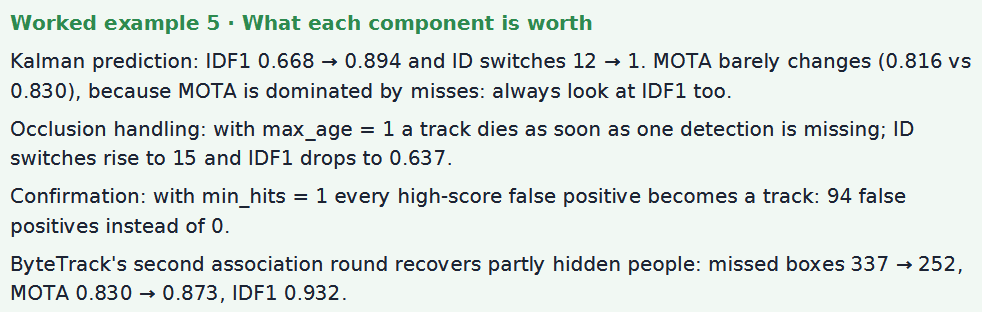

In [1]:
import sys; sys.path.insert(0, "..")    
import numpy as np
from src.simulation import make_objects, simulate
from src.tracker import SORT, ByteTrackLike, run
from src.metrics import evaluate

# same scenario as the tutorial: 12 pedestrians, an occluding pillar, noisy detector
rng = np.random.default_rng(7)
objects = make_objects(rng)
gt, dets = simulate(objects, rng)
n_gt = sum(len(g) for g in gt)
print(f"{len(objects)} objects, {n_gt} ground-truth boxes, {len(gt)} frames\n")

variants = {
    "IoU only, no Kalman": SORT(use_kf=False),     # remove the motion model
    "SORT, max_age = 1":   SORT(max_age=1),        # remove occlusion handling
    "SORT, min_hits = 1":  SORT(min_hits=1),       # remove track confirmation
    "SORT":                SORT(),                 # full SORT
    "ByteTrack-like":      ByteTrackLike(),        # SORT + second matching round
}
for name, trk in variants.items():
    m = evaluate(gt, run(trk, dets))
    print(f"{name:20s} MOTA {m['MOTA']:.3f}  IDF1 {m['IDF1']:.3f}  "
          f"IDSW {m['IDSW']:3d}  FP {m['FP']:3d}  FN {m['FN']:3d}")

12 objects, 1984 ground-truth boxes, 300 frames

IoU only, no Kalman  MOTA 0.816  IDF1 0.668  IDSW  12  FP   0  FN 354
SORT, max_age = 1    MOTA 0.808  IDF1 0.637  IDSW  15  FP   0  FN 365
SORT, min_hits = 1   MOTA 0.795  IDF1 0.878  IDSW   1  FP  94  FN 311
SORT                 MOTA 0.830  IDF1 0.894  IDSW   1  FP   0  FN 337
ByteTrack-like       MOTA 0.873  IDF1 0.932  IDSW   0  FP   0  FN 252


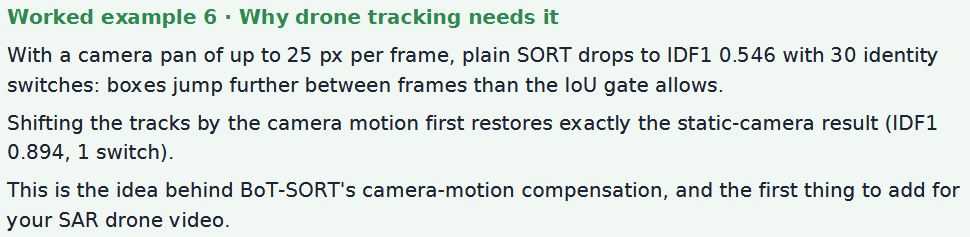

In [2]:
import sys; sys.path.insert(0, "..")      
import numpy as np
from src.simulation import make_objects, simulate
from src.tracker import SORT, Track, run
from src.metrics import evaluate

rng = np.random.default_rng(7)
objects = make_objects(rng)
gt, dets = simulate(objects, rng)
N_FRAMES = len(gt)

# drone / handheld camera: the whole image shifts sideways, up to ~25 px per frame
pan = np.cumsum(25 * np.sin(np.arange(N_FRAMES) / 12.0))     # total x shift at each frame

def shift(boxes, dx):
    out = boxes.copy()
    out[:, [0, 2]] += dx                                        # move x1 and x2
    return out

gt_cam = [[(i, b + np.r_[pan[f], 0, pan[f], 0]) for i, b in g] for f, g in enumerate(gt)]
dets_cam = [np.c_[shift(d[:, :4], pan[f]), d[:, 4]] for f, d in enumerate(dets)]

class CompensatedSORT(SORT):
    """SORT that first moves every track by the camera motion between two frames."""
    def step_with_motion(self, det, dx):
        # in practice dx (or a full homography) is estimated from the background,
        # e.g. feature matching + RANSAC or ECC image alignment
        for t in self.tracks:
            t.kf.x[0] += dx                                     # shift the box centre cx
        return self.step(det)

def run_comp(dets, pan):
    Track._next_id = 1
    trk = CompensatedSORT()
    d_pan = np.diff(np.r_[0, pan])                              # shift between frames
    return [trk.step_with_motion(d, dx) for d, dx in zip(dets, d_pan)]

d_pan = np.diff(np.r_[0, pan])
print(f"camera shift between frames: up to {np.abs(d_pan).max():.1f} px")
for label, res in [("static camera, SORT", run(SORT(), dets)),
                   ("moving camera, SORT", run(SORT(), dets_cam)),
                   ("moving camera, compensated", run_comp(dets_cam, pan))]:
    g = gt if label.startswith("static") else gt_cam
    m = evaluate(g, res)
    print(f"{label:27s}: MOTA {m['MOTA']:.3f}  IDF1 {m['IDF1']:.3f}  ID switches {m['IDSW']}")

camera shift between frames: up to 25.0 px
static camera, SORT        : MOTA 0.830  IDF1 0.894  ID switches 1
moving camera, SORT        : MOTA 0.776  IDF1 0.546  ID switches 30
moving camera, compensated : MOTA 0.830  IDF1 0.894  ID switches 1


In [3]:
import numpy as np
import cv2

# a textured "ground" image seen from the drone, and the next frame shifted by 17.3 px
rng = np.random.default_rng(1)
world = cv2.GaussianBlur(rng.random((600, 1600)).astype(np.float32), (0, 0), 3)
true_dx = 17.3
M = np.float32([[1, 0, true_dx], [0, 1, 0]])                  # shift right by true_dx
frame1 = world[:, 100:1380].copy()
frame2 = cv2.warpAffine(world, M, (1600, 600))[:, 100:1380]

(dx, dy), response = cv2.phaseCorrelate(frame1, frame2)
print(f"estimated shift: dx = {dx:.2f} px, dy = {dy:.2f} px (true {true_dx}, 0)")

estimated shift: dx = 17.16 px, dy = -0.00 px (true 17.3, 0)
